![Banner](../images/09_11_banner_rs_foundation_models.png)

# Very High Resolution: DINOv3-sat, Satlas NAIP, Scale-MAE and SAM 2

At 50 cm to 2 m a satellite image shows individual roofs, trees, field boundaries and ponds. Models
for this scale are trained on aerial and commercial imagery, and the useful output changes from one
vector per chip to dense features per patch and to object outlines. This notebook runs very high
resolution encoders on a 1.6 m WorldView-2 scene of Bangladesh and on 50 cm DeepGlobe images,
classifies fields and land cover from their patch features, and uses Segment Anything 2 (SAM 2) to
outline fields from clicks and boxes, checking every outline against hand-drawn polygons.

## Overview

### What changes at sub-metre resolution

| | 10 to 30 m (Sentinel-2, Landsat) | 0.3 to 2 m (WorldView, NAIP, aerial) |
|---|---|---|
| a pixel holds | a mixture of materials | mostly one material |
| informative signal | spectra and their change over time | shape, texture, shadow, context |
| bands | 10 to 13 including SWIR | usually RGB, sometimes NIR (WorldView-2: 8 bands) |
| typical outputs | per-pixel classes, indices | objects, outlines, counts |
| nuisances | clouds, mixed pixels | shadows, off-nadir lean, misregistration |

Spectral models trained on Sentinel-2 do not transfer to this scale; the models below were trained on
aerial or commercial imagery.

### The encoders

- **DINOv3-sat** (Meta, 2025): a ViT-7B trained by self-distillation on 493 million Maxar images,
  distilled into ViT-L and smaller models. Its dense features are among the strongest available for
  satellite imagery. The weights are gated: you must accept the licence on Hugging Face and log in.
- **SatlasPretrain NAIP Swin-B**: Swin-v2 trained with labels on 1 m US aerial imagery (NAIP).
- **Scale-MAE** ViT-L: a masked autoencoder trained on fMoW RGB imagery at 0.3 to 3 m with a
  resolution-aware position encoding.

### Dense features

A ViT with 16 pixel patches returns one feature vector per 16 x 16 pixel patch, a map 16 times
coarser than the image. `embed_raster(dense=True)` stitches the patch maps of all chips into one
georeferenced map; features can then be sampled at any point by interpolation.

### Promptable segmentation

SAM and SAM 2 (Kirillov et al. 2023; Ravi et al. 2024) return the mask of the object under a prompt:
a point, a box or a rough mask. They have no notion of classes: a click on a field returns that
field's outline, and a click on a pond returns the pond. With good prompts they delineate objects
far more sharply than patch features can, so the two are complementary: features say **what**,
SAM says **where exactly**.

## Very High Resolution with GeoLattice

| Task | GeoLattice |
|---|---|
| gated and fallback encoders | `fm.load_model("dinov3-sat-vitl16")`, `"satlas-swinb-naip"`, `"scale-mae"` |
| inputs per contract | `fm.prepare(name, da)`, `embed_raster(norm="model", dense=True)` |
| features at points | `emb.interp(x=..., y=...)` |
| probes | `fm.linear_probe`, `fm.knn_probe` |
| promptable segmentation | SAM 2 predictor (`sam2`), masks to polygons with `rasterio.features.shapes` |

### Learning objectives

1. Load a gated model, and fall back cleanly when it is not available.
2. Compute dense patch features of very high resolution imagery and view them.
3. Classify fields from features sampled at their centres, against a band-value baseline.
4. Classify DeepGlobe land cover per 8 m cell from patch features.
5. Outline fields with SAM 2 from clicks and from boxes, and score the outlines against drawn polygons.
6. Export the outlines as a GeoPackage.

### Data

| Dataset | Content |
|---|---|
| WorldView-2, Bangladesh | 8 bands, 1.6 m, 2.6 x 3 km; 566 hand-drawn crop and fallow field polygons |
| DeepGlobe land cover | 50 cm RGB tiles with masks in 7 classes |

### Contents

- Setup
- Which encoders are available
- A WorldView-2 scene and its fields
- Dense features of the scene
- Crop or fallow from patch features
- DeepGlobe land cover per 8 m cell
- Outlining fields with SAM 2
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, `sam2`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]" sam2`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

import geopandas as gpd  # field polygons
from PIL import Image  # DeepGlobe images
WV = IC / "WorldView2_BD"  # WorldView-2 scene and labels
DG = IC / "Landcover_data"  # DeepGlobe land cover

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## Which encoders are available

DINOv3-sat is tried first. Without an accepted licence and a Hugging Face login it raises an error,
which is caught; the notebook then uses Scale-MAE and Satlas NAIP, which download freely.

In [2]:
ENCODERS = []  # encoders that load on this machine
try:  # DINOv3-sat is gated
    dino = fm.load_model("dinov3-sat-vitl16", device=DEVICE)  # needs `hf auth login` after accepting the licence
    ENCODERS.append("dinov3-sat-vitl16"); del dino  # available
except Exception as e:  # not authorised or not downloaded
    print("DINOv3-sat not available:", type(e).__name__, "-", str(e).splitlines()[0][:120])  # why
ENCODERS += ["scale-mae", "satlas-swinb-naip"]  # freely downloadable fallbacks
print("encoders used:", ENCODERS)  # final list
pd.DataFrame({n: fm.model_info(n) for n in ["dinov3-sat-vitl16", "scale-mae", "satlas-swinb-naip"]}).loc[["architecture", "inputs", "weights", "notes"]]  # details

DINOv3-sat not available: OSError - You are trying to access a gated repo.
encoders used: ['scale-mae', 'satlas-swinb-naip']


,dinov3-sat-vitl16,scale-mae,satlas-swinb-naip
architecture,ViT-L/16 distilled from the 7B DINOv3 satellit...,ViT-L MAE with GSD-aware positional encoding,Swin-v2-B
inputs,RGB Maxar-like imagery (SAT-493M),RGB at any ground sample distance,NAIP RGB (1 m)
weights,facebook/dinov3-vitl16-pretrain-sat493m,torchgeo ScaleMAELarge16_Weights.FMOW_RGB,torchgeo Swin_V2_B_Weights.NAIP_RGB_SI_SATLAS
notes,Gated on Hugging Face: accept the license and ...,,


## A WorldView-2 scene and its fields

The scene is stored as one 8-band GeoTIFF with digital numbers. The encoders read RGB (bands 5, 3
and 2), scaled to 0 to 1 by the 2nd and 98th percentiles. The field polygons were drawn by hand and
labelled crop or fallow.

{'band': 8, 'y': 1889, 'x': 1647} | pixel (1.5999999999999894, -1.5999999999999508) | {'Crop': 480, 'Fallow': 87}


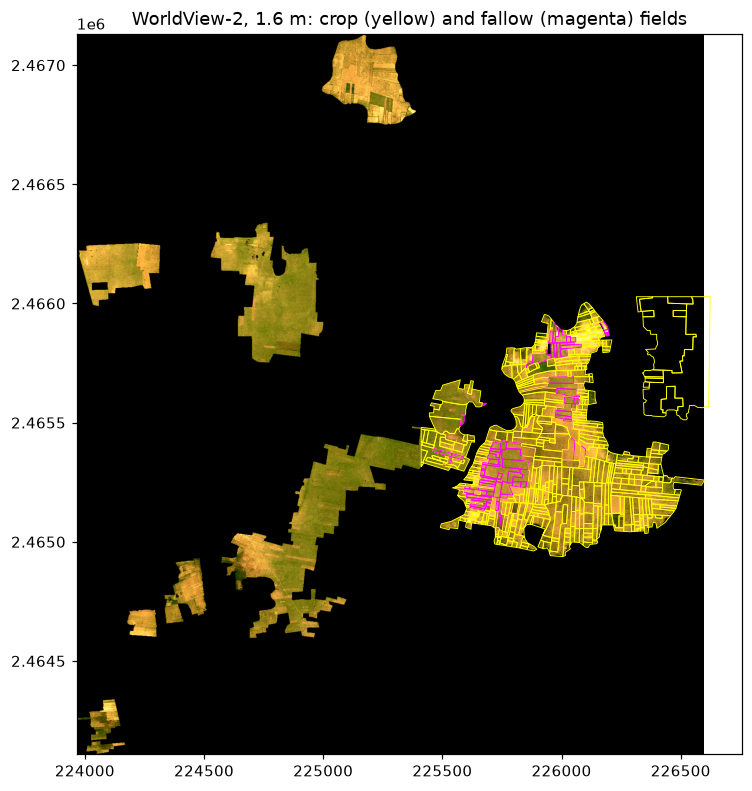

In [3]:
wv = rioxarray.open_rasterio(WV / "Images" / "multi.tif", masked=True)  # 8 bands, 1.6 m
fields = gpd.read_file(WV / "Labeled_data" / "aoi_trianing.shp").set_crs(wv.rio.crs, allow_override=True)  # polygons (no .prj: same UTM 46N grid as the image)
fields["label"] = fields["Class"].str.strip()  # crop or fallow
lo, hi = [np.nanpercentile(wv.isel(band=[4, 2, 1]).values, q) for q in (2, 98)]  # display stretch
rgb = ((wv.isel(band=[4, 2, 1]) - lo) / (hi - lo)).clip(0, 1).fillna(0)  # red, green, blue in 0..1
rgb = rgb.assign_coords(band=["red", "green", "blue"]).rio.write_crs(wv.rio.crs)  # named bands
print(dict(wv.sizes), "| pixel", wv.rio.resolution(), "|", fields["label"].value_counts().to_dict())  # summary
ext = [float(wv.x.min()), float(wv.x.max()), float(wv.y.min()), float(wv.y.max())]  # extent
fig, ax = plt.subplots(figsize=(8, 8.5))  # one panel
ax.imshow(rgb.transpose("y", "x", "band").values, extent=ext)  # image
fields.boundary.plot(ax=ax, color=fields["label"].map({"Crop": "yellow", "Fallow": "magenta"}), lw=0.6)  # polygons
ax.set_title("WorldView-2, 1.6 m: crop (yellow) and fallow (magenta) fields"); plt.show()  # draw

## Dense features of the scene

Each encoder reads the RGB scene through its contract: `fm.prepare(name, rgb, units="unit")` says
the values are already scaled to 0 to 1 and applies the model's statistics (ImageNet statistics for
Scale-MAE, none for Satlas NAIP). Chips have the model's own size, and the patch features are stitched
into one map.

In [4]:
dense, secs = {}, {}  # feature maps and run times
for n in ENCODERS:  # every available encoder
    enc = fm.load_model(n, device=DEVICE)  # load
    t0 = time.perf_counter()  # start the clock
    x = fm.prepare(n, rgb, units="unit")  # RGB is already 0..1: apply the model's statistics only
    dense[n] = enc.embed_raster(x, dense=True, norm={"method": "none"}, batch_size=8)  # (D, y, x) patch features
    secs[n] = time.perf_counter() - t0  # seconds
    del enc; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
pd.DataFrame({"feature map": {n: f"{d.sizes['embedding']} x {d.sizes['y']} x {d.sizes['x']}" for n, d in dense.items()},
              "cell size (m)": {n: round(abs(float(d.x[1] - d.x[0])), 1) for n, d in dense.items()},
              "seconds": pd.Series(secs).round(1)})  # summary

,feature map,cell size (m),seconds
scale-mae,1024 x 119 x 103,25.6,4.9
satlas-swinb-naip,1024 x 60 x 52,51.2,2.0


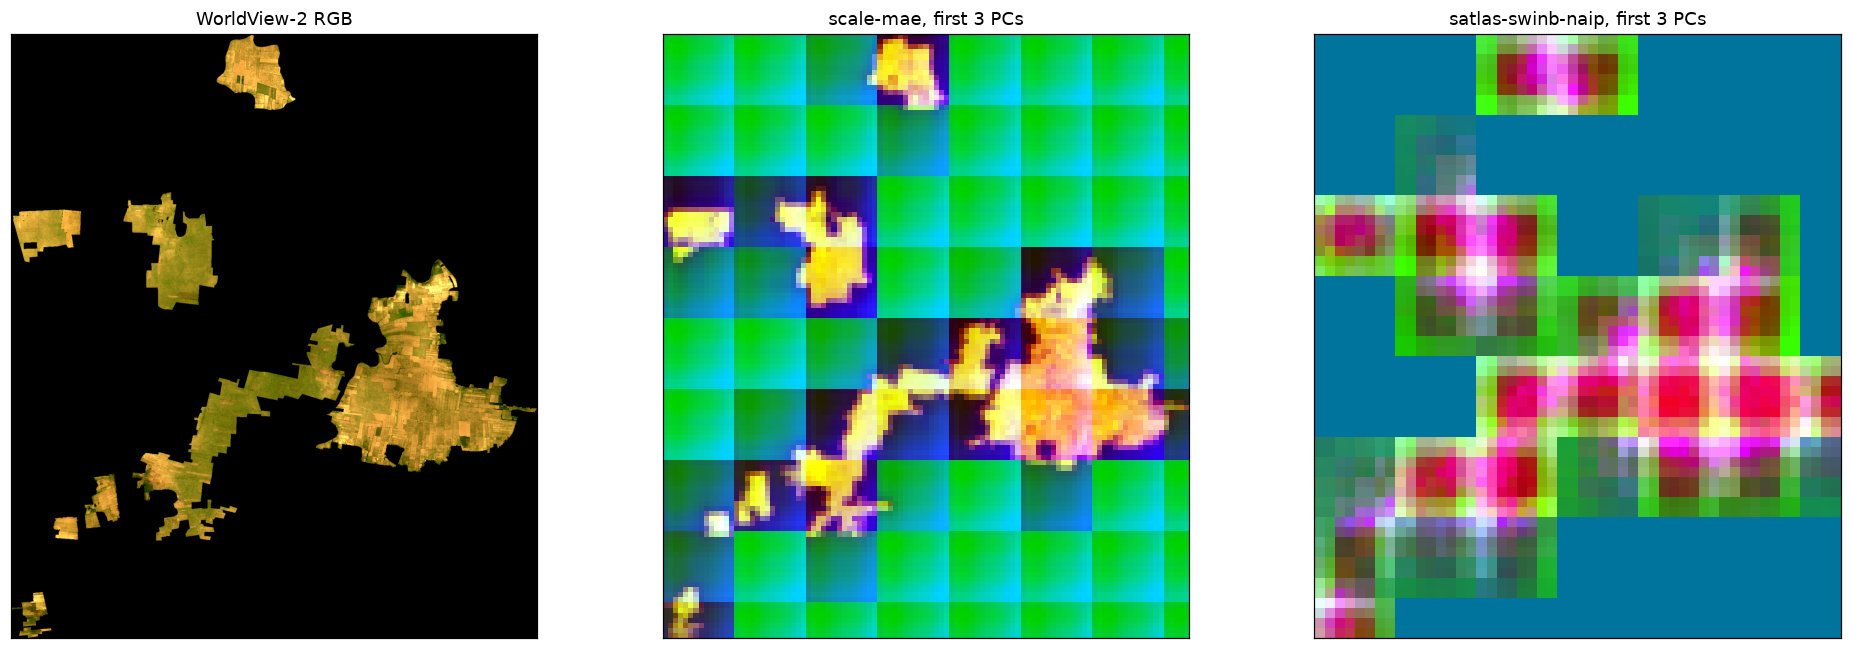

In [5]:
fig, ax = plt.subplots(1, len(dense) + 1, figsize=(6 * (len(dense) + 1), 6))  # image and feature maps
ax[0].imshow(rgb.transpose("y", "x", "band").values, extent=ext); ax[0].set_title("WorldView-2 RGB")  # image
for a, (n, d) in zip(ax[1:], dense.items()):  # every encoder
    a.imshow(fm.embedding_rgb(d).transpose("y", "x", "band"), extent=ext, interpolation="nearest"); a.set_title(f"{n}, first 3 PCs")  # features
for a in ax:  # all panels
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

Most of this scene is empty: WorldView-2 delivered only the area around the fields, and the rest is
no-data, set to zero. Both feature maps spend their first principal components on that difference, so
the fields stand out as one colour against the background. Inside the empty area the maps show the
models' own structure: Scale-MAE a smooth gradient inside each 224 pixel chip (its position encoding,
visible when the content carries no information) and Satlas one block per 256 pixel chip. Inside the
fields both vary with the field pattern, Scale-MAE at 26 m and Satlas at 51 m. Empty areas should be
masked before features are used, as the probes below do by sampling only at fields.

## Crop or fallow from patch features

Fields average about 1,200 m², a few patches each. For every polygon the features are interpolated at
its centroid (`emb.interp`), and the baseline is the mean of the 8 WorldView-2 bands in a 5 x 5 pixel
window at the same point. Fields are grouped into eight spatial clusters for cross-validation.

In [6]:
from sklearn.cluster import KMeans  # spatial groups

cent = fields.geometry.representative_point()  # a point inside every polygon
cx, cy = xr.DataArray(cent.x.values, dims="f"), xr.DataArray(cent.y.values, dims="f")  # as DataArrays
groups = KMeans(8, n_init=10, random_state=SEED).fit_predict(np.c_[cent.x, cent.y])  # spatial clusters
y_f = fields["label"].values  # crop or fallow
win = wv.rolling(y=5, x=5, center=True, min_periods=1).mean()  # 5 x 5 pixel band means
X = {"8 band means": win.interp(x=cx, y=cy, method="nearest").values.T}  # baseline features
for n, d in dense.items():  # every encoder
    X[n] = d.interp(x=cx, y=cy, method="linear").values.T  # features at the centroids
ok = np.isfinite(np.c_[tuple(X.values())]).all(1)  # points with all features
rows = {n: {"F1 (linear)": fm.linear_probe(v[ok], y_f[ok], groups=groups[ok])["mean"]["f1_macro"],
            "accuracy (kNN)": fm.knn_probe(v[ok], y_f[ok], groups=groups[ok], k=7)["mean"]} for n, v in X.items()}  # probes
print(ok.sum(), "fields |", dict(zip(*np.unique(y_f[ok], return_counts=True))))  # sample
pd.DataFrame(rows).T.round(3)

556 fields | {'Crop': np.int64(469), 'Fallow': np.int64(87)}


,F1 (linear),accuracy (kNN)
8 band means,0.664,0.903
scale-mae,0.724,0.797
satlas-swinb-naip,0.572,0.767


The labels are unbalanced (469 crop fields, 87 fallow), so macro F1 is the score to read; always
predicting "crop" would already give 84 % accuracy. On macro F1 the Scale-MAE features beat the eight
band means (about 0.72 against 0.66), while Satlas NAIP falls below them (about 0.57): Satlas sees
51 m cells, coarser than most fields. The kNN accuracy reverses the order, because with this imbalance
kNN mostly rewards getting the majority class right, and the eight bands, including the NIR bands the
RGB encoders never see, separate green crops from bare fallow well. Fields of a few hundred square
metres are at the limit of what 26 to 51 m patch features can describe.

## DeepGlobe land cover per 8 m cell

DeepGlobe tiles are 2448 pixels at 50 cm with land cover masks. Twenty tiles are embedded; each
16 pixel (8 m) patch is labelled with the majority class of its mask pixels when it covers at least
70 % of them. Tiles are the cross-validation groups, so the probe is tested on tiles it never saw.
The baseline is the mean and standard deviation of red, green and blue in each patch.

In [7]:
DG_CLASSES = pd.read_csv(DG / "class_dict.csv")  # class colours
meta = pd.read_csv(DG / "metadata.csv").query("split == 'train'").sample(20, random_state=SEED)  # 20 tiles
code = {tuple(r[["r", "g", "b"]]): k for k, (_, r) in enumerate(DG_CLASSES.iterrows())}  # colour -> class index
feats = {n: [] for n in ENCODERS}; base, lab, grp = [], [], []  # features, baseline, labels, tiles
encs = {n: fm.load_model(n, device=DEVICE) for n in ENCODERS}  # load the encoders once
for t, (_, row) in enumerate(meta.iterrows()):  # every tile
    im = np.asarray(Image.open(DG / row["sat_image_path"]).convert("RGB"), "float32")[:2432, :2432] / 255  # crop to 19 x 128 px
    mk = (np.asarray(Image.open(DG / row["mask_path"]).convert("RGB"))[:2432, :2432] > 128) * 255  # clean mask colours
    cls_px = np.vectorize(lambda r, g, b: code.get((r, g, b), 6))(mk[..., 0], mk[..., 1], mk[..., 2])  # class per pixel
    da = xr.DataArray(im.transpose(2, 0, 1), dims=("band", "y", "x"), coords={"band": ["red", "green", "blue"],
                      "y": -np.arange(2432) * 0.5, "x": np.arange(2432) * 0.5})  # tile as a raster (0.5 m)
    b = cls_px.reshape(152, 16, 152, 16).transpose(0, 2, 1, 3).reshape(152 * 152, -1)  # mask pixels per 8 m cell
    cnt = np.stack([(b == k).sum(1) for k in range(7)], 1); maj = cnt.argmax(1); pur = cnt.max(1) / 256  # majority class
    keep = (pur >= 0.7) & (maj != 6)  # pure, known cells
    rgbcell = im.reshape(152, 16, 152, 16, 3)  # pixels per cell
    base.append(np.c_[rgbcell.mean((1, 3)).reshape(-1, 3), rgbcell.std((1, 3)).reshape(-1, 3)][keep])  # baseline features
    for n, e in encs.items():  # every encoder
        d = e.embed_raster(fm.prepare(n, da, units="unit"), dense=True, norm={"method": "none"}, batch_size=8)  # patch features
        f = int(round(d.sizes["y"] / 152))  # patches per 8 m cell (1 for 16 px patches, 0.5 for Swin)
        v = d.values if f <= 1 else d.coarsen(y=f, x=f).mean().values  # cell grid
        if v.shape[1] < 152:  # coarser features (32 px Swin cells): repeat to the 8 m grid
            v = np.repeat(np.repeat(v, 152 // v.shape[1], 1), 152 // v.shape[2], 2)  # nearest upsampling
        feats[n].append(v[:, :152, :152].reshape(v.shape[0], -1).T[keep])  # features of kept cells
    lab.append(maj[keep]); grp.append(np.full(keep.sum(), t))  # labels and tile groups
del encs; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
lab, grp, base = np.concatenate(lab), np.concatenate(grp), np.concatenate(base)  # all cells
names = DG_CLASSES["name"].tolist()  # class names
print(len(lab), "cells from", len(meta), "tiles |", pd.Series(lab).map(dict(enumerate(names))).value_counts().to_dict())  # sample
sub = np.random.default_rng(SEED).choice(len(lab), min(len(lab), 20000), replace=False)  # at most 20,000 cells for the probes
res = {"RGB mean and std": fm.linear_probe(base[sub], lab[sub], groups=grp[sub])["mean"]}  # baseline
for n in ENCODERS:  # every encoder
    res[n] = fm.linear_probe(np.concatenate(feats[n])[sub], lab[sub], groups=grp[sub])["mean"]  # probe
pd.DataFrame(res).T.round(3)

456080 cells from 20 tiles | {'agriculture_land': 223482, 'urban_land': 67471, 'forest_land': 66379, 'barren_land': 36306, 'water': 33166, 'rangeland': 29276}


,accuracy,f1_macro
RGB mean and std,0.577,0.290
scale-mae,0.733,0.478
satlas-swinb-naip,0.703,0.440


At 50 cm and with six land cover classes, the patch features clearly beat simple RGB statistics: a
macro F1 of about 0.48 for Scale-MAE and 0.44 for Satlas NAIP, against 0.29 for the mean and standard
deviation of red, green and blue in each 8 m cell, with whole tiles held out. Texture and context
(roofs and roads for urban land, crowns for forest, the uniform surface of water) are what the
encoders add and colour statistics miss. Scores stay moderate because DeepGlobe's rangeland and
barren land look alike, and agriculture covers half of all cells.

## Outlining fields with SAM 2

SAM 2 receives the RGB scene once and then one prompt per field. Two kinds of prompt are compared on
thirty crop fields: a single click inside the field (SAM returns three candidate masks; the smallest
is kept, since a click inside a field may also mean the whole block of fields), and the bounding box of
the drawn polygon. Each mask is compared with its polygon by intersection over union (IoU), and the box
masks are turned into polygons and exported.

In [8]:
from rasterio.features import rasterize, shapes  # polygons <-> masks
from sam2.sam2_image_predictor import SAM2ImagePredictor  # SAM 2
from shapely.geometry import shape  # GeoJSON -> shapely

pred = SAM2ImagePredictor.from_pretrained("facebook/sam2.1-hiera-large", device=DEVICE)  # SAM 2.1 Hiera-L (cached)
img8 = (rgb.transpose("y", "x", "band").values * 255).astype("uint8")  # the scene as 8-bit RGB
amp = dict(device_type=DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda")  # mixed precision on the GPU
with torch.inference_mode(), torch.autocast(**amp):  # inference
    pred.set_image(img8)  # encode the scene once
tr = rgb.rio.transform()  # map <-> pixel
crop_fields = fields[fields["label"] == "Crop"].sample(30, random_state=SEED)  # 30 crop fields to prompt
rows, masks_box = [], {}  # scores and box masks
for i, f in crop_fields.iterrows():  # every field
    truth = rasterize([f.geometry], out_shape=img8.shape[:2], transform=tr).astype(bool)  # drawn polygon as a mask
    p = f.geometry.representative_point(); col, row = ~tr * (p.x, p.y)  # click inside the field
    x0, y0, x1, y1 = f.geometry.bounds; (c0, r0), (c1, r1) = ~tr * (x0, y1), ~tr * (x1, y0)  # bounding box in pixels
    with torch.inference_mode(), torch.autocast(**amp):  # inference
        mp, _, _ = pred.predict(point_coords=np.array([[col, row]]), point_labels=np.array([1]), multimask_output=True)  # 3 candidates
        mb, _, _ = pred.predict(box=np.array([c0, r0, c1, r1]), multimask_output=False)  # one mask
    mp = mp.astype(bool)[np.argmin(mp.sum((1, 2)))]; mb = mb[0].astype(bool)  # smallest point mask, box mask
    iou = lambda m: (m & truth).sum() / max((m | truth).sum(), 1)  # intersection over union
    rows.append({"field": i, "pixels drawn": int(truth.sum()), "IoU point": iou(mp), "IoU box": iou(mb)})  # scores
    masks_box[i] = mb  # keep for the figure and export
del pred; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
iou = pd.DataFrame(rows).set_index("field")  # scores per field
polys = [shape(g) for m in masks_box.values() for g, v in shapes(m.astype("uint8"), mask=m, transform=tr) if v == 1]  # masks -> polygons
out = gpd.GeoDataFrame({"source": ["SAM 2, box prompt"] * len(polys)}, geometry=polys, crs=wv.rio.crs)  # outlines
out.to_file(OUT / "wv2_sam2_fields.gpkg", driver="GPKG")  # export
print("written", OUT / "wv2_sam2_fields.gpkg", "|", len(out), "polygons | median field size", int(iou["pixels drawn"].median()), "pixels")  # export
pd.DataFrame({"median IoU": iou[["IoU point", "IoU box"]].median(), "share with IoU >= 0.5": (iou[["IoU point", "IoU box"]] >= 0.5).mean()}).round(2)  # summary

written outputs/wv2_sam2_fields.gpkg | 42 polygons | median field size 379 pixels


,median IoU,share with IoU >= 0.5
IoU point,0.01,0.03
IoU box,0.49,0.50


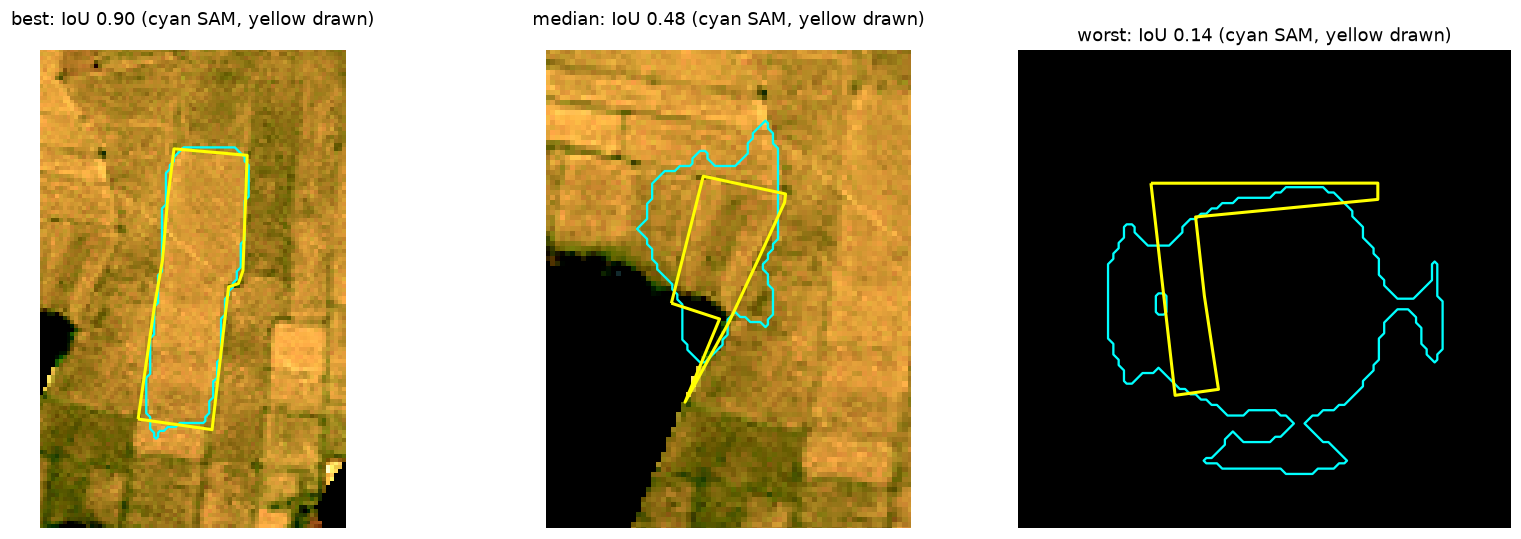

In [9]:
pick = iou.sort_values("IoU box", ascending=False).index[[0, len(iou) // 2, -1]]  # best, median and worst box result
fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three examples
for a, i, t in zip(ax, pick, ["best", "median", "worst"]):  # every example
    g = fields.loc[i].geometry; x0, y0, x1, y1 = g.buffer(40).bounds  # 40 m around the field
    a.imshow(rgb.transpose("y", "x", "band").values, extent=ext); a.set_xlim(x0, x1); a.set_ylim(y0, y1)  # zoom
    a.contour(rgb.x, rgb.y, masks_box[i], levels=[0.5], colors="cyan", linewidths=1.5)  # SAM outline of this field
    gpd.GeoSeries([g]).boundary.plot(ax=a, color="yellow", lw=2)  # drawn polygon
    a.set_title(f"{t}: IoU {iou.loc[i, 'IoU box']:.2f} (cyan SAM, yellow drawn)"); a.axis("off")  # title
plt.tight_layout(); plt.show()  # draw

A single click almost never outlines the field (median IoU about 0.01): the fields are tiny for SAM,
a median of about 380 pixels in a scene SAM shrinks to 1024 pixels on its long side, and in this
dry-season image neighbouring fields have similar colour, so a click inside a field is ambiguous. A
box around the field tells SAM what is meant, and the median IoU rises to about 0.49, with half the
fields at 0.5 or better. The best outlines follow the drawn polygon closely (IoU about 0.9); the worst
field was drawn over a part of the scene with no image data, where SAM has nothing to outline. In
practice boxes come from a detector, from a coarse map or from a cadastre, and SAM sharpens them.

## Summary and exercises

### Summary

- Very high resolution imagery is about shape, texture and context; encoders for it are trained on
  aerial and commercial images (DINOv3-sat, Satlas NAIP, Scale-MAE).
- Gated models need a licence and a login; the notebook falls back to freely available encoders.
- Dense patch features, sampled at field centroids or aggregated per cell, classify fields and land
  cover; a simple band-value baseline shows what they add.
- SAM 2 outlines objects far more sharply than any patch feature map, but the prompt decides what it
  outlines: on small, low-contrast fields a single click is ambiguous and a box works much better, and
  every outline must still be checked against reference polygons.
- Features say what, SAM says where exactly: together they turn very high resolution imagery into
  labelled vector objects.

### Exercises

1. Accept the DINOv3-sat licence, run `hf auth login` and rerun the notebook. How do its features compare?
2. Add the WorldView-2 NIR bands: embed bands 7, 5 and 3 (NIR, red, green) as false colour with
   Scale-MAE. Do crop and fallow separate better?
3. Prompt SAM 2 with a click plus a box, or with several clicks per field. Which prompt works best for the smallest fields?
4. Use the dense features to find cells similar to one pond and prompt SAM 2 at each of them to map all
   ponds in the scene.
5. Compute the crop-or-fallow probe with features averaged over the whole polygon instead of the centroid.

### References

- Bastani, F. et al. (2023). SatlasPretrain. ICCV.
- Demir, I. et al. (2018). DeepGlobe 2018. CVPR Workshops.
- Kirillov, A. et al. (2023). Segment anything. ICCV.
- Ravi, N. et al. (2024). SAM 2: segment anything in images and videos. arXiv:2408.00714.
- Reed, C. J. et al. (2023). Scale-MAE. ICCV.
- Simeoni, O. et al. (2025). DINOv3. arXiv:2508.10104.